<a href="https://colab.research.google.com/github/prangunj23/CS163-Radio-Interferometry-Project/blob/main/Visibility_Prediction_Model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount("/content/drive")
!pip install -q pyuvdata tqdm
from tqdm.auto import tqdm

Mounted at /content/drive


In [ ]:
import numpy as np
import torch

!cp -r "/content/drive/MyDrive/CS 163/cs163_tensors" /content/

X = np.load("/content/cs163_tensors/X.npy")   # uncalibrated visibilities: (10000 observations, real/imag, 214 antennas, 214 antennas)
G = np.load("/content/cs163_tensors/Y.npy")   # antenna gains: (10000 observations, real/imag, 214 antennas)
M = np.load("/content/cs163_tensors/M.npy")   # which antennas are good (True) or flagged (False): (10000, 214)

print("Uncalibrated visibilities:", X.shape)
print("Gains:", G.shape)

Uncalibrated visibilities: (10000, 2, 214, 214)
Gains: (10000, 2, 214)


In [ ]:
# Step 2: Work out the TRUE visibilities (the answers we want the model to learn)
# Each antenna i distorts the signal by its gain g_i, so what we observe is:
#     observed[i, j] = g_i * conj(g_j) * true[i, j]
# Dividing the gains back out gives the true visibility:
#     true[i, j] = observed[i, j] / (g_i * conj(g_j))

def true_visibilities(x, g, m):
    observed = torch.complex(x[:, 0].float(), x[:, 1].float())          # (batch, 214, 214) complex numbers
    gains = torch.complex(g[:, 0], g[:, 1])                             # (batch, 214) complex numbers
    gain_product = gains[:, :, None] * gains.conj()[:, None, :]         # g_i * conj(g_j) for every antenna pair
    good = m[:, :, None] & m[:, None, :] & (gain_product.abs() > 1e-6)  # skip pairs with a flagged antenna
    true = torch.where(good, observed / gain_product, torch.zeros_like(observed))
    return torch.stack([true.real, true.imag], dim=1), good             # back to (batch, real/imag, 214, 214)

In [ ]:
# Step 3: Split the observations: 80% to train on, 20% to test on later
X, G, M = torch.from_numpy(X), torch.from_numpy(G), torch.from_numpy(M)

order = torch.randperm(len(X), generator=torch.Generator().manual_seed(0))
n_train = int(0.8 * len(X))
train_ids, test_ids = order[:n_train], order[n_train:]
print(len(train_ids), "training observations,", len(test_ids), "test observations")

8000 training observations, 2000 test observations


In [ ]:
import torch.nn as nn

device = "cuda" if torch.cuda.is_available() else "cpu"
size = 2 * 214 * 214

model = nn.Sequential(
    nn.Linear(size, 256), nn.ReLU(),
    nn.Linear(256, 256), nn.ReLU(),
    nn.Linear(256, size),
).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)


def get_batch(ids):
    x, g, m = X[ids].to(device), G[ids].to(device), M[ids].to(device)
    target, good = true_visibilities(x, g, m)
    mask = good[:, None].expand(-1, 2, -1, -1).flatten(1)
    return x.float().flatten(1), target.flatten(1), mask


for epoch in tqdm(range(10)):
    shuffled = train_ids[torch.randperm(len(train_ids))]
    for start in tqdm(range(0, len(shuffled), 32)):
        x, target, mask = get_batch(shuffled[start:start + 32])
        prediction = model(x)
        loss = ((prediction - target) ** 2)[mask].mean()
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    print(f"epoch {epoch}: loss {loss.item():.4f}")

  0%|          | 0/10 [00:00<?, ?it/s]

  0%|          | 0/250 [00:00<?, ?it/s]

epoch 0: loss 6.9653


  0%|          | 0/250 [00:00<?, ?it/s]

epoch 1: loss 7.3485


...

epoch 7: loss 7.3681


  0%|          | 0/250 [00:00<?, ?it/s]

epoch 8: loss 7.1987


  0%|          | 0/250 [00:00<?, ?it/s]

epoch 9: loss 7.1245


cs163 reloaded (paths, data, losses, pipelines, results)
Loaded model from: /content/drive/MyDrive/CS 163/results/2026-10-25_011641_pranit_visibility_mlp


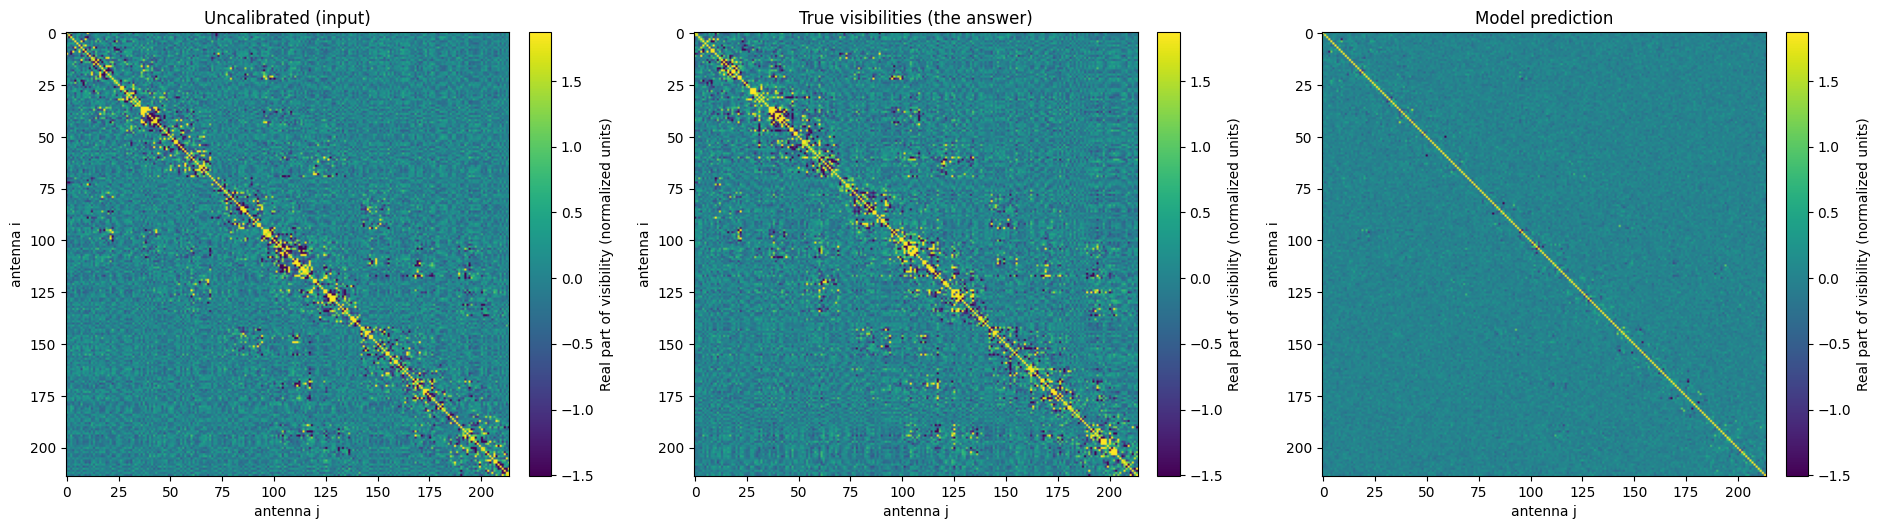

In [ ]:
# Load the saved model from the shared results folder (no retraining needed), then plot it.
# Run the cells for Steps 1-3 first; you can skip the training cell above.
import os, sys
import torch.nn as nn
import matplotlib.pyplot as plt
LIB = "/content/drive/MyDrive/CS 163/cs163_lib"
os.environ["CS163_USER"] = "pranit"

# Check that Python can see the team package (it lives in the shared CS 163 folder on Drive)
if not os.path.isdir(os.path.join(LIB, "cs163")):
    top = "/content/drive/MyDrive/CS 163"
    print("Can't find the cs163 package at", LIB)
    print("What's in My Drive/CS 163:", sorted(os.listdir(top)) if os.path.isdir(top) else "the CS 163 folder isn't in this Drive")
    raise FileNotFoundError("cs163 package not found - see the message above")
os.listdir(os.path.join(LIB, "cs163"))          # make Drive load the folder's file list
sys.path.insert(0, LIB)
import importlib
importlib.invalidate_caches()                   # make Python look at the folder again
import cs163
cs163.reload()                                  # pick up the latest results.py
from cs163 import results


device = "cuda" if torch.cuda.is_available() else "cpu"
size = 2 * 214 * 214

# 1) Rebuild the same model shape that was trained, then load its saved weights into it
model = nn.Sequential(
    nn.Linear(size, 256), nn.ReLU(),
    nn.Linear(256, 256), nn.ReLU(),
    nn.Linear(256, size),
).to(device)
run_dir = "/content/drive/MyDrive/CS 163/results/2026-10-25_011641_pranit_visibility_mlp"
results.load_model(run_dir, model, device=device)
model.eval()
print("Loaded model from:", run_dir)


def get_batch(ids):   # same as in the training cell, repeated here so that cell can be skipped
    x, g, m = X[ids].to(device), G[ids].to(device), M[ids].to(device)
    target, good = true_visibilities(x, g, m)
    mask = good[:, None].expand(-1, 2, -1, -1).flatten(1)
    return x.float().flatten(1), target.flatten(1), mask


# 2) Run the model on one test observation it never trained on
with torch.no_grad():
    x, target, mask = get_batch(test_ids[:1])
    prediction = model(x)

# 3) Plot the three panels, each with a color bar explaining what the colors mean
images = [x[0], target[0], prediction[0]]
titles = ["Uncalibrated (input)", "True visibilities (the answer)", "Model prediction"]
low, high = np.percentile(target[0].cpu().numpy(), [1, 99])   # one color scale shared by all panels

fig, axes = plt.subplots(1, 3, figsize=(19, 5.5))
for ax, img, title in zip(axes, images, titles):
    im = ax.imshow(img.reshape(2, 214, 214)[0].cpu(), vmin=low, vmax=high, cmap="viridis")
    ax.set_title(title)
    ax.set_xlabel("antenna j"); ax.set_ylabel("antenna i")
    cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    cbar.set_label("Real part of visibility (normalized units)")

plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.savefig('raw_prediction.jpg')
plt.show()

Model error:                         7.100092887878418
Error if we didn't calibrate at all: 3.1598711013793945
(lower is better - the model should beat the second number)


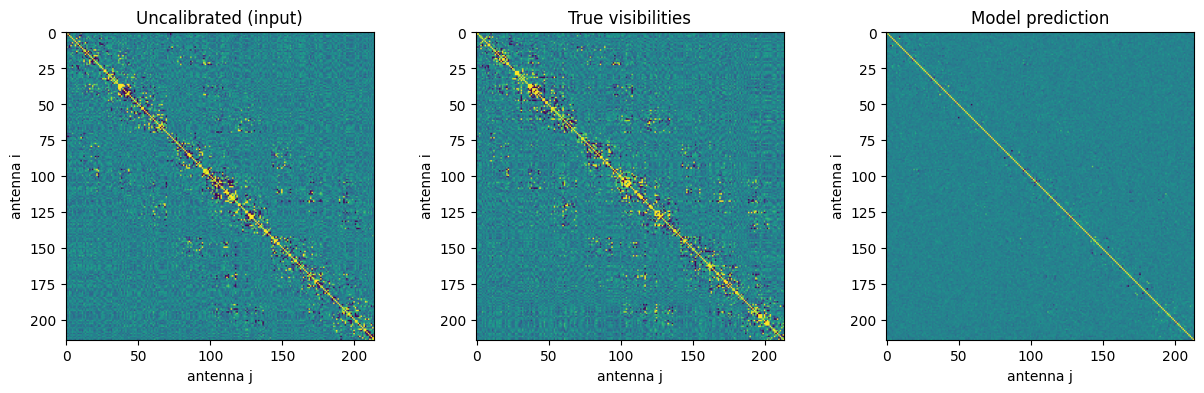

In [ ]:
# Step 5: Check how well it does on test observations it has never seen
import matplotlib.pyplot as plt

model.eval()
with torch.no_grad():
    x, target, mask = get_batch(test_ids[:100])
    prediction = model(x)
    model_error = ((prediction - target) ** 2)[mask].mean().item()
    no_calibration_error = ((x - target) ** 2)[mask].mean().item()   # error if we just used the uncalibrated data as-is

print("Model error:                        ", model_error)
print("Error if we didn't calibrate at all:", no_calibration_error)
print("(lower is better - the model should beat the second number)")

# Picture of one test observation (real part): input, the true answer, and the model's guess
images = [x[0], target[0], prediction[0]]
titles = ["Uncalibrated (input)", "True visibilities", "Model prediction"]
low, high = np.percentile(target[0].cpu().numpy(), [1, 99])
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, img, title in zip(axes, images, titles):
    ax.imshow(img.reshape(2, 214, 214)[0].cpu(), vmin=low, vmax=high)
    ax.set_title(title)
    ax.set_xlabel("antenna j"); ax.set_ylabel("antenna i")
plt.show()

In [ ]:
# Step 6: Save the results with the team's cs163 package (run this after Step 5)
# Saves to the shared folder:  CS 163/results/<date>_<time>_pranit_visibility_mlp/
import os, sys
sys.path.insert(0, "/content/drive/MyDrive/CS 163/cs163_lib")
os.environ["CS163_USER"] = "pranit"          # labels the run with your name
import cs163
cs163.reload()                               # pick up the latest results.py
from cs163 import results

results.save_predictions(
    "visibility_mlp",
    model=model,
    prediction=prediction,
    target=target,
    mask=mask,
    test_ids=test_ids[:100],
    metrics={"model_error": model_error, "no_calibration_error": no_calibration_error},
    params={"hidden_layers": [256, 256], "lr": 1e-4, "epochs": 10, "batch_size": 32},
    notes="MLP mapping uncalibrated visibilities -> true visibilities (observed / (g_i * conj(g_j))).",
    fig=fig,
)

cs163 reloaded (paths, data, losses, pipelines, results)
saved -> /content/drive/MyDrive/CS 163/results/2026-10-25_011641_pranit_visibility_mlp


PosixPath('/content/drive/MyDrive/CS 163/results/2026-10-25_011641_pranit_visibility_mlp')